# 08 发生率预报：两条基线与评分

BNBU DS 2043 / DI-3。在已经建好的 2° × 30 天网格上，拟合两条**非机器学习**基线，并在验证、测试和后期 holdout 上评分。不训练 ML 模型，不改已有目录，不推送 GitHub。

评价永远报告 Brier、相对对数似然、PR-AUC 和校准，不用准确率作主指标。

## 0 公式与泄漏规则

对每个区域（中国及周边矩形、Pacific、并集）单独估计，只用该区域的掩膜格和事件。

**基线 1：长期历史发生率（静态，只靠训练窗）**

对格子 \(c\)，设 \(n_{\mathrm{train}}\) 为完整训练窗数（535），

\[
p^{\mathrm{emp}}_c = \frac{\#\{T \in \mathrm{train}: N_{c,T} \ge 1\}}{n_{\mathrm{train}}}, \qquad
\lambda_c = \frac{\sum_{T \in \mathrm{train}} N_{c,T}}{n_{\mathrm{train}}}, \qquad
p^{\mathrm{Pois}}_c = 1 - e^{-\lambda_c}.
\]

主报告用经验频率 \(p^{\mathrm{emp}}\)；Poisson 形式作为并列诊断。2025–2026 不进入这些估计。若训练期该格从未阳性，则 \(p=0\)，评分时把概率裁到 \([10^{-6}, 1-10^{-6}]\)，以免对数损失爆炸。

**基线 2：近期活动时空平滑（运行式，无未来泄漏）**

时间常数 \(\tau = 3 \times 365.25\) 天，空间高斯带宽 \(\sigma = 200\) km，截断于 \(4\sigma = 800\) km。空间距离是到格中心的 **haversine**（经度差按日界线卷绕），不用欧氏 lon/lat，也不用 StandardScaler 修补几何。

\[
s_c(T) = \sum_{e:\, t_e < T_{\mathrm{start}}} \exp\bigl(-(T_{\mathrm{start}}-t_e)/\tau\bigr)\, \exp\bigl(-d_{\mathrm{gc}}(c,e)^2 / (2\sigma^2)\bigr),
\]

\[
\alpha = \frac{N_{\mathrm{train}}}{\sum_{c,T \in \mathrm{train}} s_c(T)}, \qquad
\lambda_c(T) = \alpha\, s_c(T), \qquad
P_c(T) = 1 - e^{-\lambda_c(T)}.
\]

\(\alpha\) 只在完整训练窗上用 Poisson MLE（总计数匹配）估计，不在验证/测试/holdout 上重估。窗 \(T\) 的特征只用发震时刻严格早于 \(T_{\mathrm{start}}\) 的事件：验证可用训练历史；测试可用训练+验证+更早的测试窗；holdout 可用 \(T\) 之前的全部历史（含 2017–2024 及更早的 holdout 窗）。

**常数阳性率对照：** 同一评价集上，训练格窗的全局阳性率，对所有格、所有窗相同。

相对对数似然定义为 \(\mathrm{LL}(p) - \mathrm{LL}(p_{\mathrm{const}})\)，越高越好。Brier skill 为 \(1 - \mathrm{Brier}/\mathrm{Brier}_{\mathrm{const}}\)。PR-AUC 是 sklearn 的 `average_precision_score`。

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rate_forecast_lib import (
    load_and_verify_catalog, build_windows, build_cell_mask, assign_events,
    mark_historical_activity, longterm_rates, kernel_scores, KERNEL_TAU_DAYS,
    KERNEL_SIGMA_KM, KERNEL_CUTOFF_KM, PROB_FLOOR,
)
from rate_forecast_plots import FIG, plot_longterm_rate_map, plot_calibration

pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 160)
ROOT = Path("/workspace/08_rate_forecast")
print("tau_days", KERNEL_TAU_DAYS, "sigma_km", KERNEL_SIGMA_KM, "cutoff_km", KERNEL_CUTOFF_KM, "prob_floor", PROB_FLOOR)

tau_days 1095.75 sigma_km 200.0 cutoff_km 800.0 prob_floor 1e-06


## 1 读取网格产物并拟合长期发生率

若网格产物已存在则直接读取（与上一本笔记本或 `run_pipeline.py` 一致），并再跑一遍核对计数。

windows 754 cells 3594 union events 6524
locked event counts in this union file (main only):
{'china_rectangle': 4220, 'PB_Pacific': 2188, 'overlap': 74, 'union': 6334}
train windows: 535
                p_empirical                                                        lambda_poisson                                                         \
                      count      mean       std  min  25%  50%       75%       max          count      mean       std  min  25%  50%       75%       max   
region                                                                                                                                                     
china_rectangle       988.0  0.004512  0.014519  0.0  0.0  0.0  0.001869  0.166355          988.0  0.005782  0.020673  0.0  0.0  0.0  0.001869  0.284112   
pacific              2632.0  0.000818  0.007510  0.0  0.0  0.0  0.000000  0.216822         2632.0  0.001084  0.011775  0.0  0.0  0.0  0.000000  0.392523   
union                3594.0  0.0

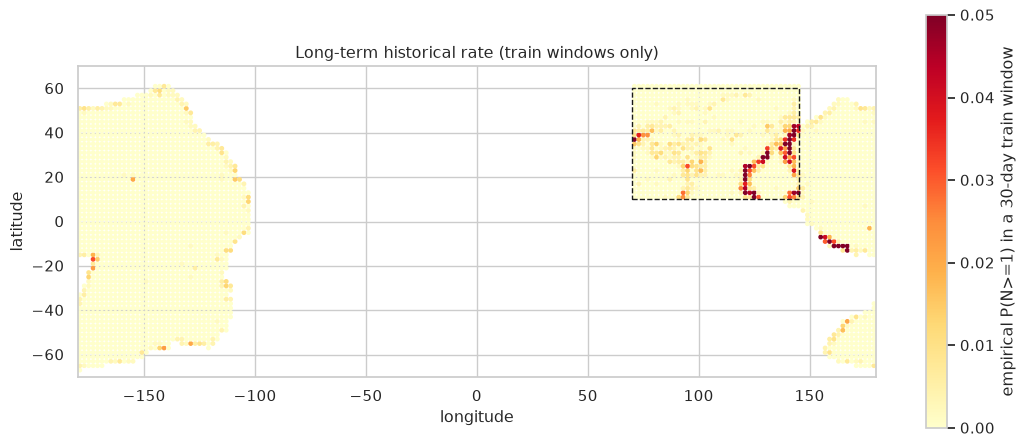

In [2]:
windows = pd.read_csv(ROOT / "windows.csv", parse_dates=["window_start", "window_end"])
cells = pd.read_csv(ROOT / "cells_mask.csv")
ev = pd.read_csv(ROOT / "events_union_assigned.csv", parse_dates=["time_utc"])
# events_union_assigned is union only; longterm/kernel only need union-region events.
print("windows", len(windows), "cells", len(cells), "union events", len(ev))
print("locked event counts in this union file (main only):")
main = ev[ev.catalog_role == "main_1965_2024"]
print({
    "china_rectangle": int(main.china_rectangle.sum()),
    "PB_Pacific": int(main.PB_Pacific.sum()),
    "overlap": int((main.china_rectangle & main.PB_Pacific).sum()),
    "union": int(len(main)),
})
rates_map = longterm_rates(ev, windows, cells)
rates = pd.concat(rates_map.values(), ignore_index=True)
print("train windows:", int((windows.split == "train").sum()))
print(rates.groupby("region")[["p_empirical", "lambda_poisson", "p_poisson"]].describe().round(6))
rates.to_csv(ROOT / "longterm_cell_rates.csv", index=False)
fig = plot_longterm_rate_map(rates, cells, FIG / "baseline_longterm_p_map.png")
plt.show()
plt.close(fig)

## 2 近期活动核：在训练窗上估计 \(\alpha\)，再对全部窗递推

实现是按时间窗递推：先对当前窗打分，再把该窗内事件加入下一窗的历史。因此测试窗不会用到该窗或未来事件；holdout 可以用 2017–2024。

In [3]:
# Reuse scores already written by run_pipeline.py if present; still print alpha.
diag = pd.read_csv(ROOT / "train_baseline_diagnostics.csv")
display(diag)
print("alpha is identical across eval sets of the same region (not refit on the historically-active subset).")

,region,eval_set,p_const_train,lambda_const_train,kernel_alpha,n_train_events_region,sum_s_train,n_train_pos,n_train_cw
0,china_rectangle,all_mask_cells,0.004512,0.005782,0.005277,3056,579097.474796,2385,528580
1,china_rectangle,historically_active,0.013633,0.017468,0.005277,3056,579097.474796,2385,174945
2,pacific,all_mask_cells,0.000818,0.001084,0.006539,1526,233365.193319,1152,1408120
3,pacific,historically_active,0.009613,0.012734,0.006539,1526,233365.193319,1152,119840
4,union,all_mask_cells,0.001825,0.002368,0.005506,4553,826843.029954,3509,1922790
5,union,historically_active,0.012191,0.015818,0.005506,4553,826843.029954,3509,287830


alpha is identical across eval sets of the same region (not refit on the historically-active subset).


## 3 验证 / 测试 / 后期 holdout 评分

两个评价集：全部掩膜格，以及训练期历史活动格。三个区域分别报告。主基线是长期经验频率与近期核；Poisson 长期式与常数阳性率作对照。

In [4]:
metrics = pd.read_csv(ROOT / "metrics_baselines.csv")
show = [
    "region", "split", "eval_set", "model",
    "n_cells", "n_windows", "n_events", "n_positive", "prevalence",
    "brier", "brier_skill_vs_const", "rel_log_likelihood_vs_const",
    "mean_log_loss", "pr_auc",
]
# Headline models
head = metrics[metrics.model.isin(["longterm_empirical", "recent_kernel", "constant_prevalence"])]
print("=== all mask cells ===")
display(head[head.eval_set == "all_mask_cells"][show].reset_index(drop=True))
print("=== historically active cells ===")
display(head[head.eval_set == "historically_active"][show].reset_index(drop=True))
print()
print("Poisson long-term diagnostic is in metrics_baselines.csv alongside the primary empirical rate.")
pois = metrics[metrics.model == "longterm_poisson"][show]
display(pois.reset_index(drop=True))

=== all mask cells ===


,region,split,eval_set,model,n_cells,n_windows,n_events,n_positive,prevalence,brier,brier_skill_vs_const,rel_log_likelihood_vs_const,mean_log_loss,pr_auc
0,china_rectangle,val,all_mask_cells,longterm_empirical,988,97,725,427,0.004456,0.004186,0.056182,745.993023,0.020782,0.092428
1,china_rectangle,val,all_mask_cells,recent_kernel,988,97,725,427,0.004456,0.004474,-0.008667,590.579515,0.022404,0.106104
2,china_rectangle,val,all_mask_cells,constant_prevalence,988,97,725,427,0.004456,0.004436,0.000000,0.000000,0.028566,0.004456
3,china_rectangle,test,all_mask_cells,longterm_empirical,988,96,430,357,0.003764,0.003606,0.038520,523.286459,0.019317,0.065883
4,china_rectangle,test,all_mask_cells,recent_kernel,988,96,430,357,0.003764,0.003695,0.014788,498.114352,0.019582,0.038472
5,china_rectangle,test,all_mask_cells,constant_prevalence,988,96,430,357,0.003764,0.003750,0.000000,0.000000,0.024834,0.003764
6,china_rectangle,holdout,all_mask_cells,longterm_empirical,988,22,120,93,0.004279,0.003998,0.061485,162.704328,0.020126,0.103280
7,china_rectangle,holdout,all_mask_cells,recent_kernel,988,22,120,93,0.004279,0.004090,0.040076,151.098369,0.020660,0.108764
8,china_rectangle,holdout,all_mask_cells,constant_prevalence,988,22,120,93,0.004279,0.004260,0.000000,0.000000,0.027612,0.004279
9,pacific,val,all_mask_cells,longterm_empirical,2632,97,435,270,0.001058,0.000993,0.060128,690.566567,0.005630,0.087584


=== historically active cells ===


,region,split,eval_set,model,n_cells,n_windows,n_events,n_positive,prevalence,brier,brier_skill_vs_const,rel_log_likelihood_vs_const,mean_log_loss,pr_auc
0,china_rectangle,val,historically_active,longterm_empirical,327,97,698,413,0.013021,0.012208,0.050092,405.454985,0.056692,0.095410
1,china_rectangle,val,historically_active,recent_kernel,327,97,698,413,0.013021,0.012914,-0.004842,259.998428,0.061278,0.112777
2,china_rectangle,val,historically_active,constant_prevalence,327,97,698,413,0.013021,0.012851,0.000000,0.000000,0.069475,0.013021
3,china_rectangle,test,historically_active,longterm_empirical,327,96,411,339,0.010799,0.010321,0.034518,298.907917,0.050441,0.069181
4,china_rectangle,test,historically_active,recent_kernel,327,96,411,339,0.010799,0.010583,0.010077,201.540649,0.053543,0.040013
5,china_rectangle,test,historically_active,constant_prevalence,327,96,411,339,0.010799,0.010690,0.000000,0.000000,0.059963,0.010799
6,china_rectangle,holdout,historically_active,longterm_empirical,327,22,117,90,0.012510,0.011664,0.055956,88.085292,0.055046,0.106580
7,china_rectangle,holdout,historically_active,recent_kernel,327,22,117,90,0.012510,0.011913,0.035820,71.319121,0.057377,0.113502
8,china_rectangle,holdout,historically_active,constant_prevalence,327,22,117,90,0.012510,0.012355,0.000000,0.000000,0.067291,0.012510
9,pacific,val,historically_active,longterm_empirical,224,97,393,249,0.011460,0.010701,0.055681,216.888359,0.052794,0.094881



Poisson long-term diagnostic is in metrics_baselines.csv alongside the primary empirical rate.


,region,split,eval_set,model,n_cells,n_windows,n_events,n_positive,prevalence,brier,brier_skill_vs_const,rel_log_likelihood_vs_const,mean_log_loss,pr_auc
0,china_rectangle,val,all_mask_cells,longterm_poisson,988,97,725,427,0.004456,0.004195,0.054261,721.198515,0.021041,0.092499
1,china_rectangle,test,all_mask_cells,longterm_poisson,988,96,430,357,0.003764,0.003668,0.021922,477.676324,0.019798,0.063337
2,china_rectangle,holdout,all_mask_cells,longterm_poisson,988,22,120,93,0.004279,0.003958,0.070946,159.433961,0.020277,0.129755
3,china_rectangle,val,historically_active,longterm_poisson,327,97,698,413,0.013021,0.012233,0.048089,380.660478,0.057474,0.095484
4,china_rectangle,test,historically_active,longterm_poisson,327,96,411,339,0.010799,0.010509,0.016924,253.297782,0.051894,0.066500
5,china_rectangle,holdout,historically_active,longterm_poisson,327,22,117,90,0.012510,0.011542,0.065813,84.814925,0.055501,0.133938
6,pacific,val,all_mask_cells,longterm_poisson,2632,97,435,270,0.001058,0.000998,0.055026,687.092691,0.005644,0.088154
7,pacific,test,all_mask_cells,longterm_poisson,2632,96,218,199,0.000788,0.000791,-0.005401,335.184519,0.005090,0.048187
8,pacific,holdout,all_mask_cells,longterm_poisson,2632,22,59,54,0.000933,0.000933,-0.001066,113.056155,0.005494,0.047139
9,pacific,val,historically_active,longterm_poisson,224,97,393,249,0.011460,0.010764,0.050092,213.414483,0.052954,0.095500


## 4 校准

分位数分箱：横轴为箱内平均预报概率，纵轴为观测阳性频率。对角线表示校准良好。

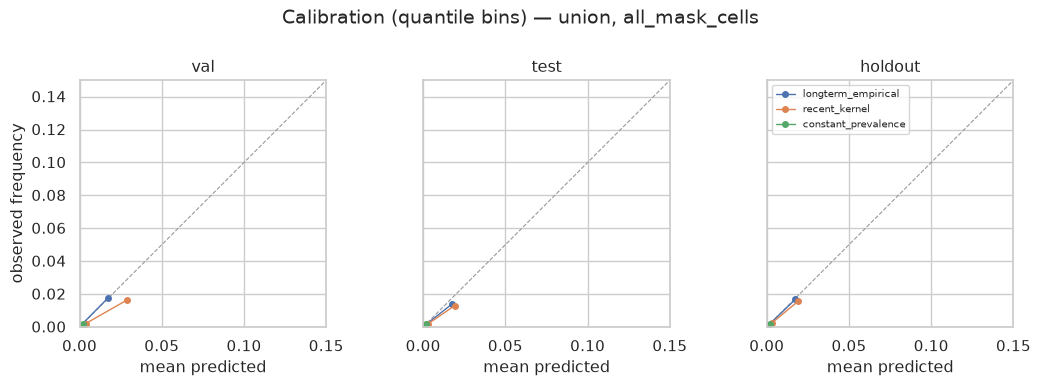

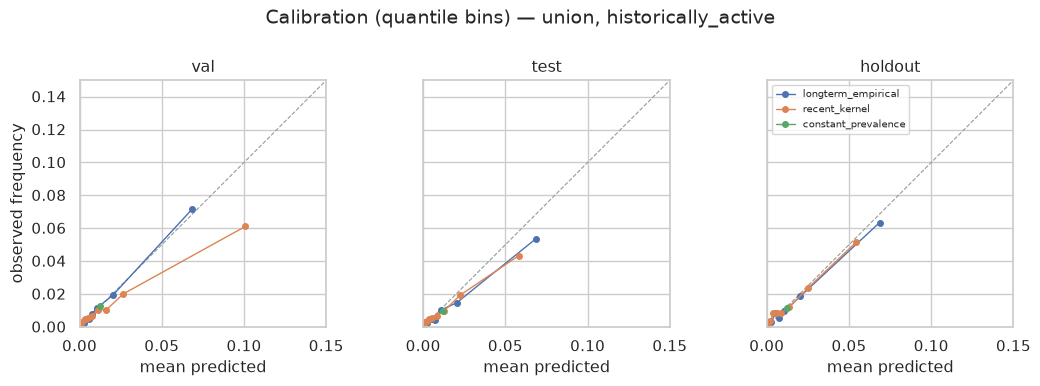

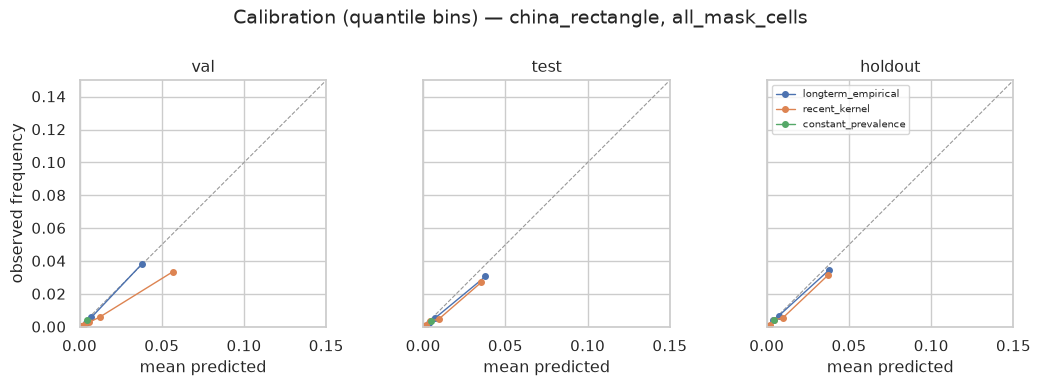

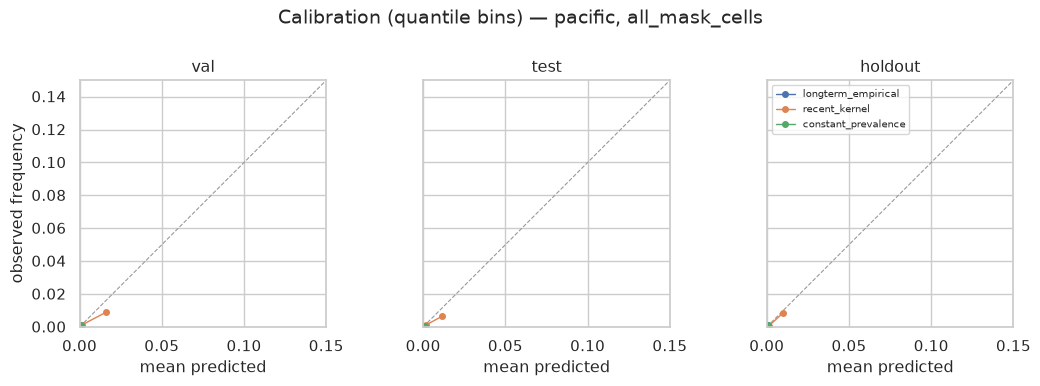

In [5]:
cal = pd.read_csv(ROOT / "calibration_bins.csv")
for region, evs, fname in [
    ("union", "all_mask_cells", "calibration_union_all.png"),
    ("union", "historically_active", "calibration_union_active.png"),
    ("china_rectangle", "all_mask_cells", "calibration_china_all.png"),
    ("pacific", "all_mask_cells", "calibration_pacific_all.png"),
]:
    fig = plot_calibration(cal, region, evs, FIG / fname)
    plt.show()
    plt.close(fig)

## 5 读数注意事项（仍不是模型选型结论）

- 在多数验证/测试/holdout 组合上，**长期经验频率**的 Brier 和相对对数似然优于这个未经调参的近期核，也优于常数阳性率。这是当前固定核（\(	au=3\) 年，\(\sigma=200\) km，单一训练期 \(lpha\)）的结果，不是已经证明「核平滑无用」。核参数没有在验证集上搜索，本阶段也不做超参数选择。
- 中国及周边验证集上，近期核的 Brier skill 相对常数对照为负；并集验证全集上也接近零。校准图用于检查是否过冲近期活跃格。
- 历史活动格上的阳性率大约是全掩膜的 6–12 倍（大量从未发生过 M≥5.5 的格子把全掩膜阳性率压低）。两个评价集都要报告。
- 完整 30 天窗的并集事件数是训练 4,553、验证 1,130、测试 633、holdout 178，小于按日历年分段的 4,558 / 1,133 / 643，因为跨段窗被排除。18 条主表并集事件和 12 条 holdout 并集事件因此不进标签，但仍可按其发震时刻进入后续窗历史。
- 最后一条 holdout 窗 `[2026-11-07, 2026-12-07)` 越过官方抓取终点 `2026-11-26T07:43:30Z`，按合同整窗剔除；其中 7 条并集事件（至 2026-11-25 01:38:45Z）没有对应标签窗。

产出：`metrics_baselines.csv`，`calibration_bins.csv`，`train_baseline_diagnostics.csv`，`longterm_cell_rates.csv`，`methodology.json`，以及 `figures/baseline_*.png` 与 `figures/calibration_*.png`。